# Módulo 5 — Textura (GLCM) y criterio D

| | |
|---|---|
| **Responde** | Extracción de características (texturas) · metodología 6 |
| **Código** | `textura_criterio_d.py` (en esta misma carpeta) |
| **Recibe** | el canal V de la imagen mejorada y la máscara |
| **Devuelve** | atributos GLCM; D estimado (0-5) |
| **Responsable** | Lucas D'Elia |

> Las funciones se programan en `textura_criterio_d.py`. Este cuaderno sólo las llama, grafica y discute.
> Para guardar una figura para el informe: `graficos.guardar_figura(fig, "nombre")`.
> Para comprobar el módulo: `python main.py --revisar` desde la carpeta del repo.

In [1]:
# Permite usar el código de las otras carpetas del repo
import sys
sys.path.insert(0, "../..")

# Recarga los cambios que hagas en los archivos .py sin reiniciar el cuaderno
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
from modulos.m0_carga_de_datos import carga_de_datos
from modulos.m1_mejoramiento import mejoramiento
from modulos.m3_segmentacion import segmentacion
from modulos.m5_textura_criterio_d import textura_criterio_d
from modulos.m7_clasificacion_resultados import clasificacion_resultados as m7
from modulos.herramientas import graficos
from modulos.herramientas.procesamiento_completo import procesar, procesar_todos

graficos.aplicar_estilo()

## 1. Atributos GLCM en PH2 (entrenamiento)

- [x] Justificar `NIVELES` y `DISTANCIA` (probar 2 o 3 valores).
- [x] Boxplots de cada atributo por diagnóstico y por D del dermatólogo.

Se usa la **máscara automática de M3**, la misma que usa el pipeline, y sólo imágenes de entrenamiento. `completar_d` ajusta con la tabla real de `main.py`.

In [2]:
from scipy import stats

filas = []
for nombre in carga_de_datos.nombres("entrenamiento"):
    caso = carga_de_datos.cargar_caso(nombre)
    img, valida, _ = mejoramiento.mejorar(caso.imagen)
    mascara = segmentacion.segmentar(img, valida)
    v = mejoramiento.a_hsv(img)[..., 2]
    fila = {"nombre": nombre, "D_derm": caso.d_dermatologo, "diagnostico": caso.diagnostico, "sospechosa": caso.sospechosa, "dice": segmentacion.dice(mascara, caso.mascara_ref)}
    for niveles in (8, 16, 32, 64):
        for distancia in (1, 2, 4):
            for k, x in textura_criterio_d.atributos_glcm(v, mascara, distancia, niveles).items():
                fila[f"{niveles}_{distancia}_{k}"] = x
    filas.append(fila)
exploracion = pd.DataFrame(filas)
print("Dice de M3 contra la referencia: mediana", round(exploracion["dice"].median(), 3), "| mínimo", round(exploracion["dice"].min(), 3))

# Spearman de cada atributo con D para cada combinación de niveles y distancia
rho = pd.DataFrame({f"{n} niveles, d = {d}": {k: stats.spearmanr(exploracion[f"{n}_{d}_{k}"], exploracion["D_derm"]).statistic
                                              for k in textura_criterio_d.ATRIBUTOS}
                    for n in (8, 16, 32, 64) for d in (1, 2, 4)}).T
rho.round(3)

Dice de M3 contra la referencia: mediana 0.931 | mínimo 0.501


,energia,entropia,contraste,idm,correlacion,cluster_shade,cluster_prominence
"8 niveles, d = 1",-0.307,0.352,-0.005,0.037,0.372,0.223,0.397
"8 niveles, d = 2",-0.295,0.344,-0.016,0.049,0.375,0.222,0.398
"8 niveles, d = 4",-0.283,0.348,0.047,0.013,0.366,0.222,0.396
"16 niveles, d = 1",-0.273,0.313,-0.031,0.123,0.382,0.224,0.389
"16 niveles, d = 2",-0.257,0.303,-0.035,0.131,0.391,0.223,0.386
"16 niveles, d = 4",-0.248,0.301,0.059,0.052,0.372,0.225,0.388
"32 niveles, d = 1",-0.255,0.290,-0.041,0.124,0.392,0.221,0.382
"32 niveles, d = 2",-0.243,0.274,-0.037,0.134,0.398,0.221,0.382
"32 niveles, d = 4",-0.229,0.279,0.055,0.069,0.374,0.220,0.383
"64 niveles, d = 1",-0.244,0.280,-0.043,0.109,0.398,0.222,0.382


**Resultado:** ni `NIVELES` ni `DISTANCIA` cambian mucho lo que importa. `correlacion` queda entre 0,37 y 0,40 en todas las combinaciones, casi empatada con `cluster_prominence` (entre 0,38 y 0,40). Se deja **32 niveles** (conserva detalle sin que la matriz de 32 × 32 quede casi vacía) y **distancia 1** (la más simple, y no pierde nada).

**Lo que sorprende:** `contraste`, el atributo que uno elegiría por intuición, casi no se relaciona con D (ρ ≈ −0,04). Lo que sigue a D es `correlacion` y `cluster_prominence`. Una lectura posible, que falta confirmar, es que miden más la heterogeneidad a escala grande (regiones claras y oscuras) que la rugosidad fina.

PosixPath('/Users/lucasdelia/Desktop/7mo Cuatri ITBA /16.63 - Procesamiento de Señales e Imágenes Biomédicas/TPF/TPI/PSIB2026Q2-TPI-Grupo02-CassanoNieto-DElia-Ortega/informe/figuras/m5_atributos.pdf')

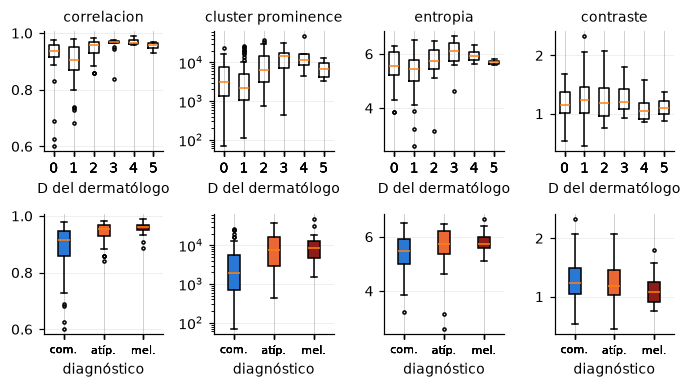

In [3]:
# Tabla con los parámetros elegidos, con las columnas que usa elegir_atributo_d
tabla = exploracion[["nombre", "D_derm", "diagnostico", "sospechosa"]].copy()
for k in textura_criterio_d.ATRIBUTOS:
    tabla[f"glcm_{k}"] = exploracion[f"{textura_criterio_d.NIVELES}_{textura_criterio_d.DISTANCIA}_{k}"]

mostrar = ["correlacion", "cluster_prominence", "entropia", "contraste"]
fig, ax = plt.subplots(2, 4, figsize=(6.3, 3.6), sharex="row")
for a, k in zip(ax[0], mostrar):
    a.boxplot([tabla.loc[tabla["D_derm"] == d, f"glcm_{k}"] for d in range(6)], tick_labels=range(6), flierprops={"markersize": 2})
    a.set_title(k.replace("_", " ")); a.set_xlabel("D del dermatólogo")
    if k == "cluster_prominence": a.set_yscale("log")
for a, k in zip(ax[1], mostrar):
    cajas = a.boxplot([tabla.loc[tabla["diagnostico"] == d, f"glcm_{k}"] for d in range(3)], tick_labels=["com.", "atíp.", "mel."],
                      patch_artist=True, flierprops={"markersize": 2})
    for caja, d in zip(cajas["boxes"], range(3)):
        caja.set_facecolor(graficos.COLOR_DIAGNOSTICO[d])
    a.tick_params(axis="x", labelsize=7); a.set_xlabel("diagnóstico")
    if k == "cluster_prominence": a.set_yscale("log")
fig.tight_layout()
graficos.guardar_figura(fig, "m5_atributos")

## 2. Criterio D adaptado

- [x] Elegir el atributo (`elegir_atributo_d`) y los umbrales; acuerdo con el D del dermatólogo.
- [x] Discutir la limitación: un solo atributo global para cinco estructuras distintas (y cómo lo mejora M6).

Se comparan dos formas de poner los umbrales, con **validación cruzada dentro de entrenamiento** (4 partes, 20 repeticiones) para no medir sobre las mismas imágenes con las que se ajusta:
- **medianas:** puntos medios entre las medianas de cada D.
- **cuantiles:** umbrales que reparten el D estimado como el del dermatólogo, que es lo que hace `ajustar_umbrales_d`.

In [4]:
print(textura_criterio_d.correlaciones_con_d(tabla).round(3).to_string())
columna = textura_criterio_d.elegir_atributo_d(tabla)
print("\nElegido:", columna)

def partes_estratificadas(grupos, partes, semilla):
    """Reparte las imágenes en partes con proporciones de grupos parecidas.

    Entra: grupos   array con el grupo de cada imagen
           partes   cantidad de partes
           semilla  entero, para que dé siempre lo mismo
    Sale : array int con el número de parte de cada imagen
    """
    rng = np.random.default_rng(semilla)
    parte = np.zeros(len(grupos), int)
    for grupo in np.unique(grupos):
        indices = rng.permutation(np.flatnonzero(grupos == grupo))
        parte[indices] = (np.arange(len(indices)) + rng.integers(partes)) % partes
    return parte

def umbrales_medianas(x, d):
    """Pone cada umbral en el punto medio entre las medianas de dos valores de D seguidos.

    Entra: x   array float con el atributo de cada imagen
           d   array int con el D del dermatólogo
    Sale : array float con los umbrales
    """
    presentes = np.unique(d)
    medianas = np.maximum.accumulate([np.median(x[d == k]) for k in presentes])
    medianas = np.interp(np.arange(presentes.max() + 1), presentes, medianas)
    return (medianas[:-1] + medianas[1:]) / 2

x, y, sospechosa = tabla[columna].to_numpy(), tabla["D_derm"].to_numpy(), tabla["sospechosa"].to_numpy()
filas = []
for metodo, ajustar in (("medianas", umbrales_medianas), ("cuantiles", textura_criterio_d.ajustar_umbrales_d)):
    for semilla in range(20):
        estimado = np.zeros(len(y), int)
        parte = partes_estratificadas(np.minimum(y, 3), 4, semilla)
        for k in range(4):
            u = ajustar(x[parte != k], y[parte != k])
            estimado[parte == k] = [textura_criterio_d.estimar_d(valor, u) for valor in x[parte == k]]
        filas.append({"umbrales": metodo, "acierto exacto": (estimado == y).mean(), "error medio": np.abs(estimado - y).mean(),
                      "D estimado = 5": (estimado == 5).sum(), "kappa": m7.kappa_cohen(estimado, y),
                      "AUC sospechosa": m7.auc(estimado, sospechosa)})
comparacion = pd.DataFrame(filas).groupby("umbrales").mean().round(3)
referencia = {"acierto exacto": (y == np.median(y)).mean(), "error medio": np.abs(y - np.median(y)).mean()}
print("\nReferencia, decir siempre la mediana:", {k: round(float(v), 3) for k, v in referencia.items()})
print("D del dermatólogo (real) con estas imágenes: AUC sospechosa =", round(m7.auc(y, sospechosa), 3))
comparacion

glcm_correlacion           0.392
glcm_cluster_prominence    0.382
glcm_entropia              0.290
glcm_cluster_shade         0.221
glcm_idm                   0.124
glcm_contraste            -0.041
glcm_energia              -0.255

Elegido: glcm_correlacion

Referencia, decir siempre la mediana: {'acierto exacto': 0.371, 'error medio': 0.921}
D del dermatólogo (real) con estas imágenes: AUC sospechosa = 0.924


,acierto exacto,error medio,D estimado = 5,kappa,AUC sospechosa
umbrales,,,,,
cuantiles,0.297,1.043,4.80,0.057,0.740
medianas,0.206,1.422,27.15,0.044,0.731


In [5]:
# Tabla para el informe y comparación final, ajustando con todo entrenamiento
umbrales = textura_criterio_d.ajustar_umbrales_d(x, y)
estimado = np.array([textura_criterio_d.estimar_d(valor, umbrales) for valor in x])
print("Umbrales sobre", columna, np.round(umbrales, 4))
graficos.guardar_tabla(comparacion.reset_index(), "m5_umbrales_d", decimales=2)
pd.crosstab(pd.Series(y, name="D dermatólogo"), pd.Series(estimado, name="D estimado"))

Umbrales sobre glcm_correlacion [0.8787 0.9516 0.9697 0.973  0.9794]


D estimado,0,1,2,3,4,5
D dermatólogo,,,,,,
0,4,12,5,1,2,0
1,16,22,9,2,3,0
2,3,14,13,6,1,2
3,1,2,5,3,2,0
4,0,0,5,1,0,2
5,0,2,2,0,0,0


**Decisión:** umbrales por **cuantiles** sobre `correlacion`. Con medianas se estimaba D = 5 unas 27 veces, cuando en entrenamiento hay sólo 4 imágenes así; eso infla el TDS sin motivo.

**Limitación que hay que decir en el informe:** el D estimado es **débil como medida de D**. Acierta el valor exacto en cerca de 3 de cada 10 imágenes, menos que decir siempre la mediana (37 %), y su acuerdo con el dermatólogo es casi nulo (κ ≈ 0,06). Es esperable: un solo número global de textura no puede contar cinco estructuras distintas (red, glóbulos, estrías, regresión, velo).

**Lo que sí aporta:** separa sospechosas de comunes (AUC ≈ 0,74), mientras que un D constante no separa nada (AUC 0,5). Aun así queda lejos del D del dermatólogo (AUC 0,92). Ese 0,74 es de entrenamiento: en prueba baja a 0,60 y su intervalo incluye al 0,5 (ver el cuaderno de M7). Por eso conviene evaluar el TDS **también** con los contrastes de M6, que miran *dónde* está cada cosa en vez de un solo número global.

**Una decisión que condiciona a M7:** se elige el atributo que más *crece* con D, porque `completar_d` no le pasa el signo a `estimar_d`. Con estos datos no cambia el resultado: los dos atributos más relacionados ya crecen con D.